# Part 5: which subsidized properties are at risk, and can we predict it?

Parts 1 to 4 describe need at the state level. This part asks a property-level question where a predictive model has real room: **when a property's last
subsidy ends, is the property re-subsidized within three years?** (`src/preservation.py`). It uses the NHPD subsidy history.

* **Event:** a property whose last subsidy ended (reason "End Date Passed") in 2011 to 2023 and that no other subsidy covered at that point. 12,822 events.
* **Label:** a new subsidy starts within three years of the end and runs past it, as recorded in the October 2026 snapshot. Fixed horizon, so every event
  has the same chance of being observed.
* **Features known at the time:** size (total and assisted units), program group, how many subsidies had ended, duration, start year, and state market
  conditions (rent to income, vacancy, rent growth, burden, renter share, unemployment) from the year before.
* **Test:** time split. Train on events through 2015, test on 2019 to 2023 (a gap so label windows do not overlap); a second split trains through 2017 and tests 2020 to 2023.

**Two limits come with the data and shape what can be claimed.** The history only contains subsidies that lapsed without renewal (renewals extend the same record), so a
model trained on it estimates the chance of rescue *given a lapse*, not the chance that a property leaves the stock. And 93 percent of events are HOME-program properties
(HOME affordability periods end by design), with 758 HUD-program events, 86 LIHTC, and 12 RHS.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

import preservation as P
from viz import apply_style, SERIES, save_figure, SURFACE, MUTED, BASELINE, INK_2, dot, tile_map, SEQUENTIAL

apply_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
abbr = panel.groupby("state_fips").state_abbr.first()
ev = P.build_events()
ev.to_csv("outputs/tables/preservation_events.csv", index=False)

## 1. The events

In [2]:
t = ev.groupby("group").resub_3y.agg(events="size", rescued="sum", rate="mean")
display(t.round(3))
yr = ev.groupby("Y").resub_3y.agg(events="size", rate="mean")
display(yr.T.round(3))
print(f"{len(ev)} events, {ev.resub_3y.sum()} rescued within three years ({ev.resub_3y.mean():.1%}); the rescue rate rose from {yr.rate.iloc[:3].mean():.1%} (2011 to 2013) to {yr.rate.iloc[-2:].mean():.1%} (2022 to 2023)")
tr, te = P.split(ev)
print(f"main split: train {len(tr)} events ({tr.resub_3y.sum()} rescued), test {len(te)} ({te.resub_3y.sum()} rescued)")

,events,rescued,rate
group,,,
home_only,11932,114,0.010
hud,758,70,0.092
lihtc,86,3,0.035
other,34,1,0.029
rhs,12,1,0.083


Y,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0
events,1270.000,961.000,914.000,1008.000,1080.000,1053.00,896.000,1000.000,884.000,970.000,979.000,938.000,869.000
rate,0.003,0.007,0.021,0.014,0.013,0.01,0.008,0.011,0.005,0.008,0.014,0.039,0.045


12822 events, 189 rescued within three years (1.5%); the rescue rate rose from 1.0% (2011 to 2013) to 4.2% (2022 to 2023)
main split: train 5233 events (58 rescued), test 4640 (102 rescued)


The rescue rate is low and not stable over time, so a model's *absolute* probabilities will drift; the test below measures how well it **ranks** properties, which is what a
targeting decision needs.

## 2. Which model, which features?

Logistic regression (the econometric model), a random forest, and gradient boosting, on six feature sets from size only to everything. AUC with a 90 percent bootstrap
interval, average precision, and the share of rescued properties found in the 20 percent ranked highest ("capture at 20 percent"; 0.20 is chance).

In [3]:
rows = []
for split in ("main", "robust"):
    tr, te = P.split(ev, split)
    y = te.resub_3y.values
    for fs, cols in P.FEATURE_SETS.items():
        for kind in ("logit", "forest", "boosting"):
            p = P.fit_predict(tr, te, cols, kind)
            lo, hi = P.bootstrap_metric(y, p, roc_auc_score, n=300)
            rows.append({"split": split, "features": fs, "model": kind, "auc": roc_auc_score(y, p), "auc_low": lo, "auc_high": hi,
                         "avg_precision": average_precision_score(y, p), "capture_top20": P.capture(y, p), "test_events": len(y), "test_rescued": int(y.sum()), "base_rate": y.mean()})
res = pd.DataFrame(rows)
res.to_csv("outputs/tables/preservation_model_results.csv", index=False)
main = res[res.split == "main"]
display(main.pivot(index="features", columns="model", values="auc").reindex(list(P.FEATURE_SETS)).round(3))
display(res[res.split == "robust"].pivot(index="features", columns="model", values="auc").reindex(list(P.FEATURE_SETS)).round(3))
b = main[(main.features == "size only") & (main.model == "logit")].iloc[0]
print(f"base rate in the test period {b.base_rate:.3f}; size-only logit: AUC {b.auc:.3f} ({b.auc_low:.2f} to {b.auc_high:.2f}), average precision {b.avg_precision:.3f}, capture at 20 percent {b.capture_top20:.2f}")

model,boosting,forest,logit
features,,,
size only,0.797,0.581,0.823
program only,0.583,0.586,0.584
size + program,0.809,0.728,0.817
property,0.814,0.743,0.826
market only,0.518,0.536,0.508
property + market,0.779,0.722,0.798


model,boosting,forest,logit
features,,,
size only,0.762,0.590,0.838
program only,0.582,0.584,0.582
size + program,0.807,0.690,0.833
property,0.803,0.689,0.838
market only,0.380,0.525,0.606
property + market,0.772,0.719,0.829


base rate in the test period 0.022; size-only logit: AUC 0.823 (0.79 to 0.85), average precision 0.079, capture at 20 percent 0.65


C:\Users\erick\AppData\Local\Temp\ipykernel_21756\3437129985.py:17: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


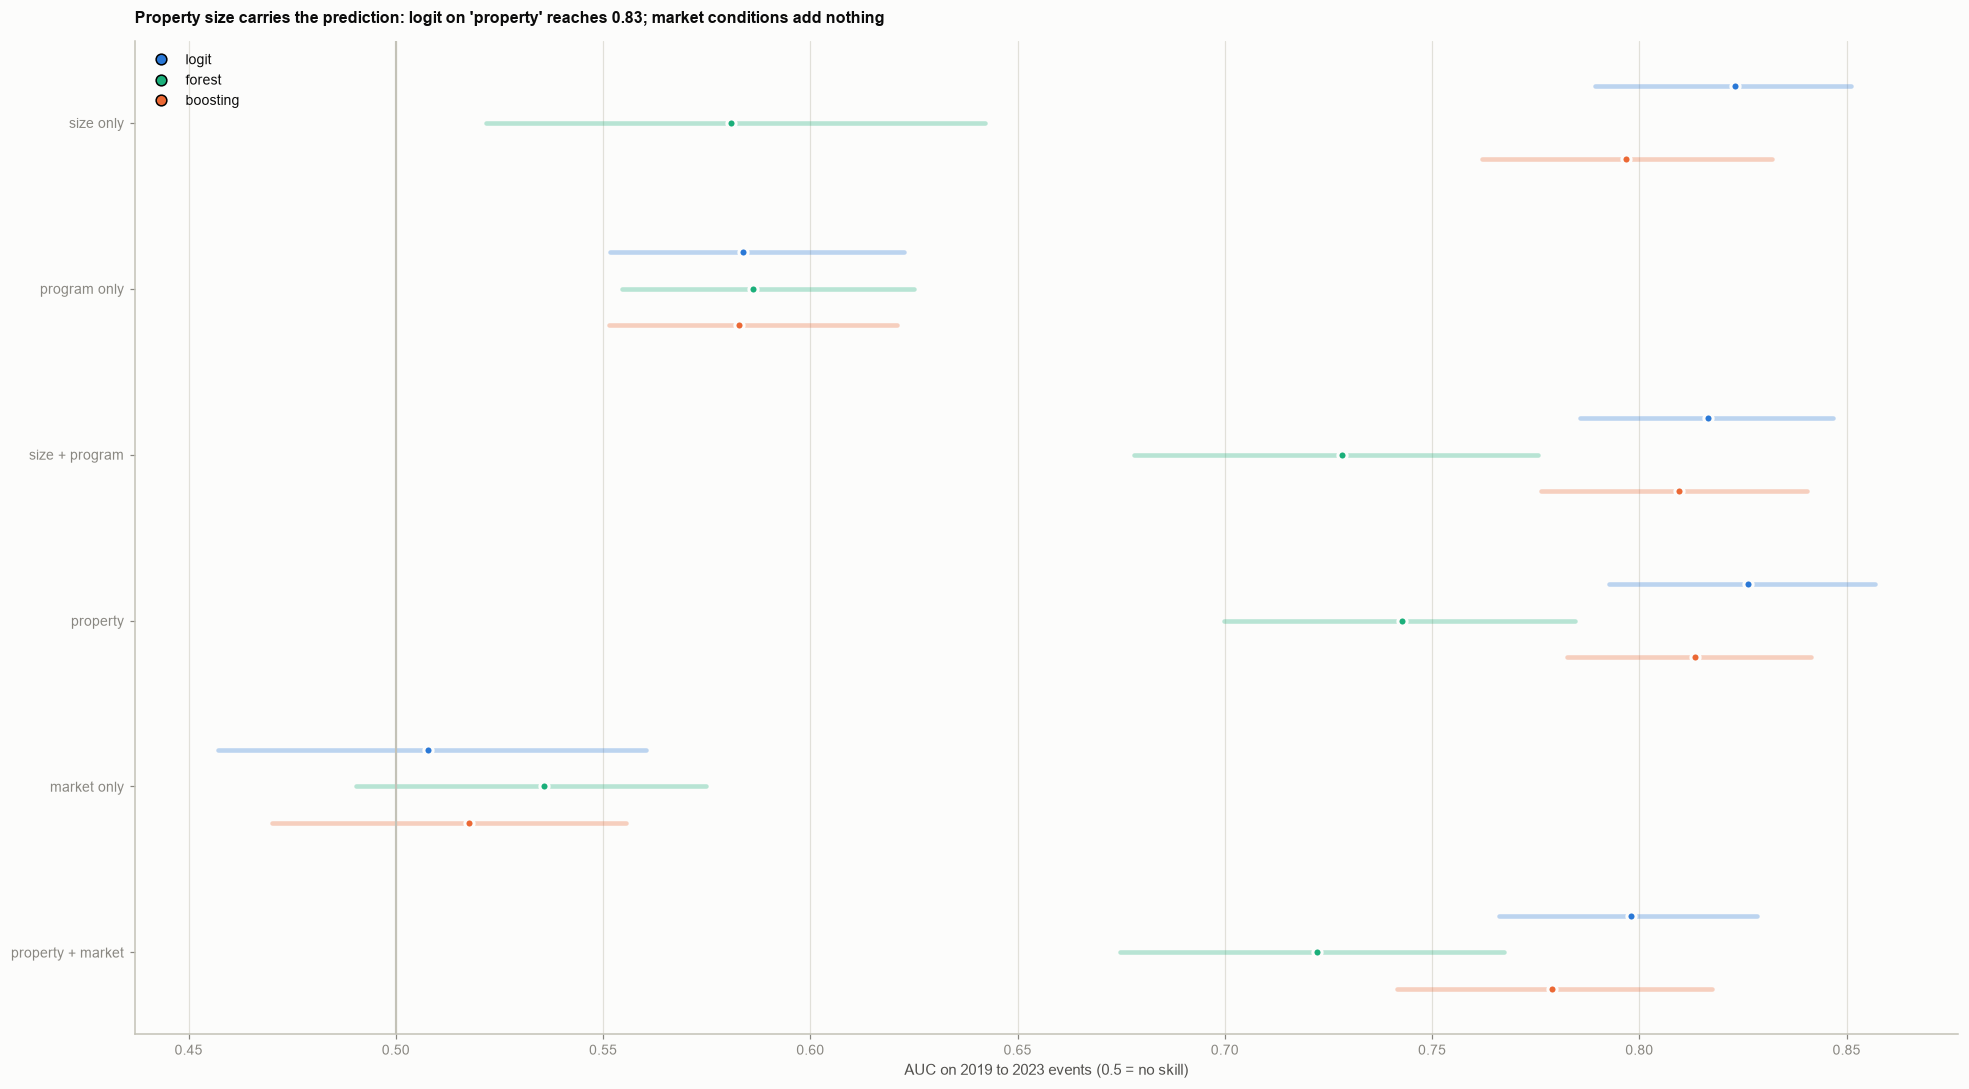

In [4]:
fig, ax = plt.subplots(figsize=(18, 10))
order = list(P.FEATURE_SETS)
colors = {"logit": SERIES[0], "forest": SERIES[2], "boosting": SERIES[1]}
for k, kind in enumerate(("logit", "forest", "boosting")):
    d = main[main.model == kind].set_index("features").reindex(order)
    y = np.arange(len(order)) + (k - 1) * 0.22
    ax.plot([d.auc_low, d.auc_high], [y, y], color=colors[kind], alpha=0.3, lw=3, solid_capstyle="round")
    for yy, a in zip(y, d.auc):
        dot(ax, a, yy, colors[kind])
ax.axvline(0.5, color=BASELINE, lw=1.4)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC on 2019 to 2023 events (0.5 = no skill)")
handles = [plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=colors[k], markersize=7) for k in colors]
ax.legend(handles, list(colors), loc="upper left", frameon=False)
best = main.loc[main.auc.idxmax()]
ax.set_title(f"Property size carries the prediction: {best.model} on '{best.features}' reaches {best.auc:.2f}; market conditions add nothing", fontsize=10.5, loc="left")
fig.tight_layout()
save_figure(fig, "51_model_comparison", part="05_preservation")
plt.show()

## 3. What the logit says

Odds ratios from a logit fitted on all events, with state-clustered standard errors. Size is entered as the log of total units, so the odds ratio is for a doubling of the
property. This is an association in a noisy label, not a causal effect of size.

In [5]:
cols = ["log_total_units"] + [f"g_{g}" for g in P.GROUPS if g != "home_only"]
X = sm.add_constant(ev[cols].astype(float))
fit = sm.Logit(ev.resub_3y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": ev.state_fips})
orr = pd.DataFrame({"odds ratio": np.exp(fit.params), "low": np.exp(fit.conf_int()[0]), "high": np.exp(fit.conf_int()[1]), "p": fit.pvalues})
orr.loc["log_total_units"] = [2 ** fit.params["log_total_units"], 2 ** fit.conf_int().loc["log_total_units", 0], 2 ** fit.conf_int().loc["log_total_units", 1], fit.pvalues["log_total_units"]]
display(orr.drop(index="const").round(3).rename(index={"log_total_units": "doubling of total units"}))
Xm = sm.add_constant(ev[cols + P.MARKET].astype(float).fillna(ev[P.MARKET].median()))
fm = sm.Logit(ev.resub_3y, Xm).fit(disp=0, cov_type="cluster", cov_kwds={"groups": ev.state_fips})
print("market variables, jointly (Wald test, state-clustered):", fm.wald_test(", ".join(f"{m} = 0" for m in P.MARKET), scalar=True))

,odds ratio,low,high,p
doubling of total units,1.852,1.660,2.066,0.000
g_hud,1.641,0.832,3.239,0.153
g_lihtc,0.682,0.232,2.002,0.486
g_rhs,5.993,0.701,51.226,0.102
g_other,0.359,0.044,2.930,0.339


market variables, jointly (Wald test, state-clustered): <Wald test (chi2): statistic=39.29324357025271, p-value=6.269980356440012e-07, df_denom=6>


group,home_only,hud
band,,
1-10,0.004,0.000
11-25,0.022,0.023
26-50,0.033,0.053
51-100,0.073,0.132
101-200,0.073,0.191
200+,NaN,0.277


C:\Users\erick\AppData\Local\Temp\ipykernel_21756\1362070592.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


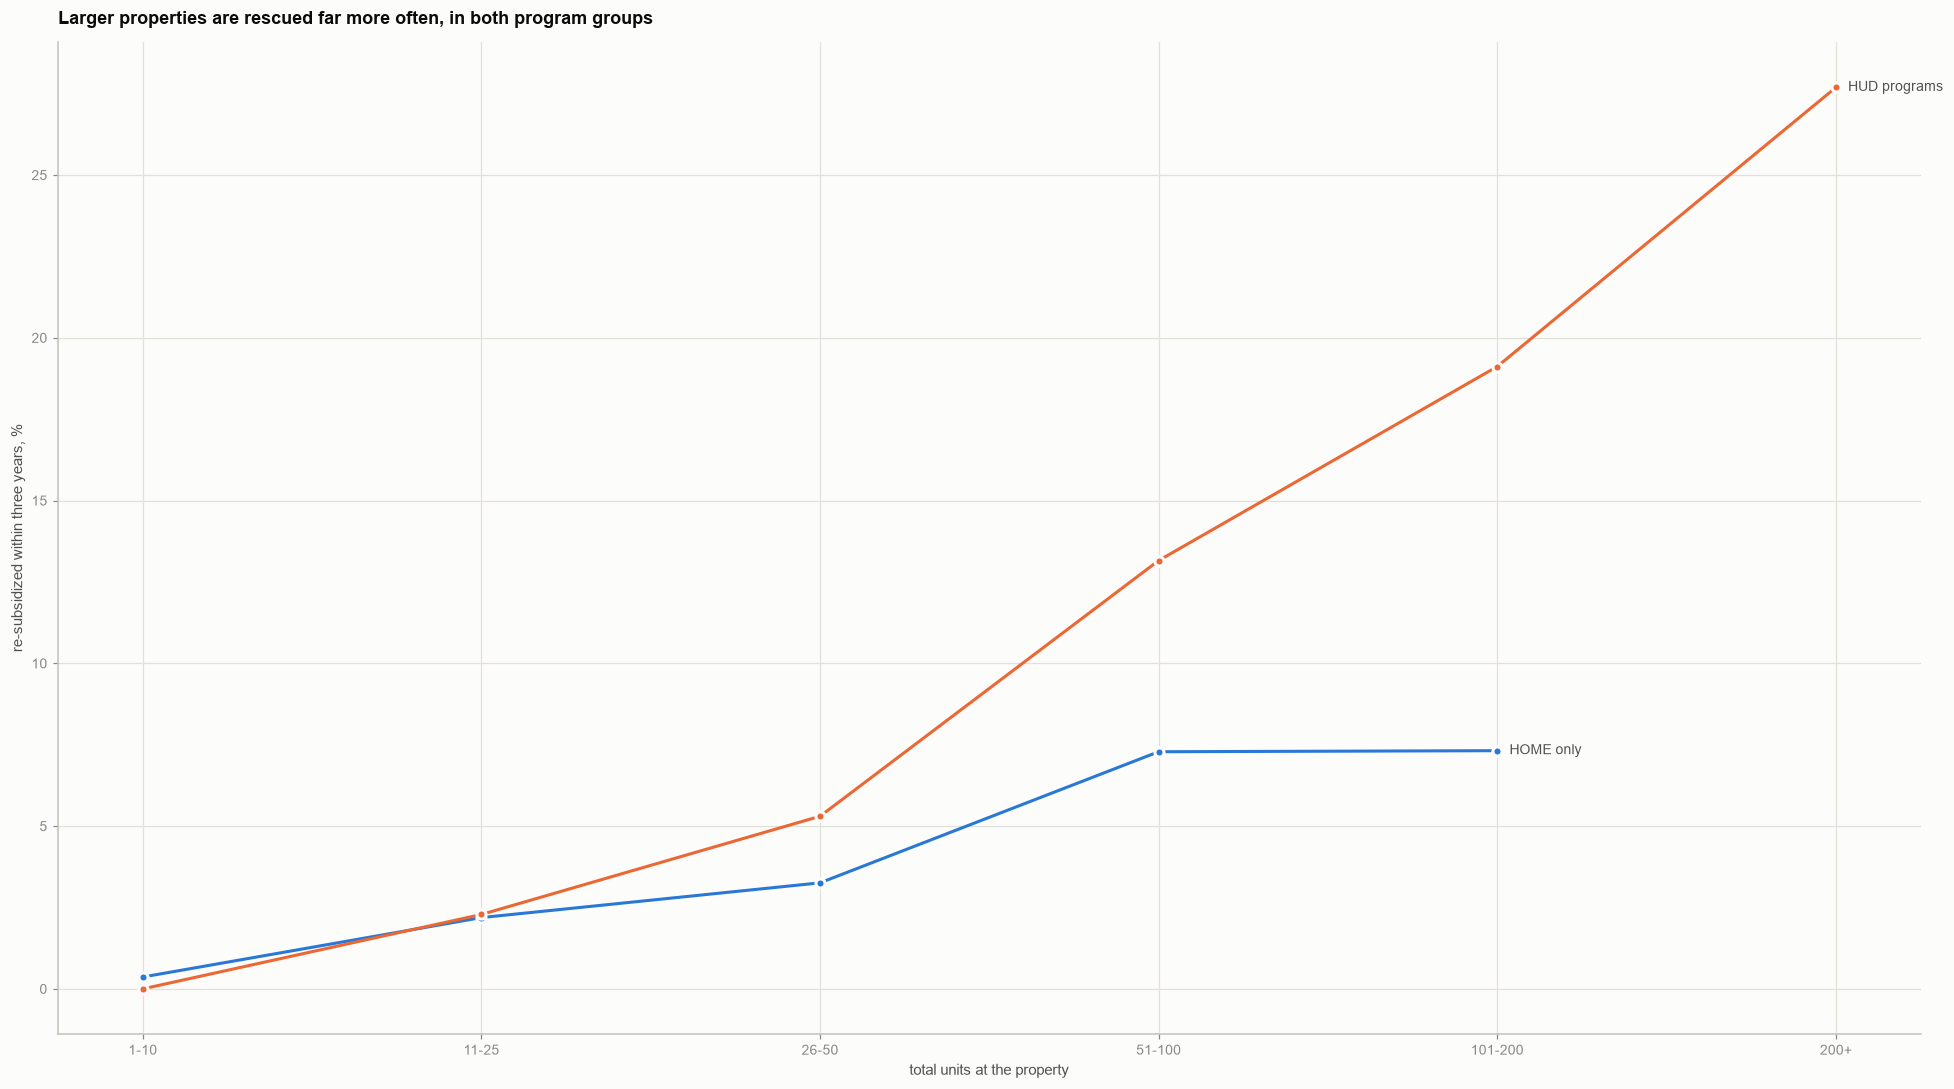

In [6]:
bands = pd.cut(ev.total_units, [0, 10, 25, 50, 100, 200, 10000], labels=["1-10", "11-25", "26-50", "51-100", "101-200", "200+"])
sz = ev.assign(band=bands).groupby(["band", "group"], observed=True).resub_3y.agg(["mean", "size"]).reset_index()
sz = sz[sz.group.isin(["home_only", "hud"]) & (sz["size"] >= 30)]
display(sz.pivot(index="band", columns="group", values="mean").round(3))
fig, ax = plt.subplots(figsize=(18, 10))
for g, c, lab in (("home_only", SERIES[0], "HOME only"), ("hud", SERIES[1], "HUD programs")):
    d = sz[sz.group == g]
    ax.plot(d.band.astype(str), 100 * d["mean"], color=c)
    for x, v in zip(d.band.astype(str), d["mean"]):
        dot(ax, x, 100 * v, c)
    ax.annotate(lab, (d.band.astype(str).iloc[-1], 100 * d["mean"].iloc[-1]), xytext=(8, 0), textcoords="offset points", fontsize=9, color=INK_2, va="center")
ax.set_xlabel("total units at the property"); ax.set_ylabel("re-subsidized within three years, %")
ax.set_title("Larger properties are rescued far more often, in both program groups", fontsize=11.5, loc="left")
fig.tight_layout()
save_figure(fig, "51_rescue_by_size", part="05_preservation")
plt.show()

## 4. Calibration

Five equal groups of the test events by predicted probability (main split, size and program logit).

In [7]:
tr, te = P.split(ev)
te = te.assign(p=P.fit_predict(tr, te, P.FINAL_COLS, "logit"))
te["quintile"] = pd.qcut(te.p.rank(method="first"), 5, labels=False) + 1
cal = te.groupby("quintile").agg(predicted=("p", "mean"), observed=("resub_3y", "mean"), events=("p", "size"))
display(cal.round(3))

,predicted,observed,events
quintile,,,
1,0.001,0.001,928
2,0.001,0.003,928
3,0.003,0.010,928
4,0.007,0.028,928
5,0.051,0.068,928


## 5. Applying it to what expires next (2026 to 2035)

21,678 active properties have a last active subsidy ending between 2026 and 2035 (properties with an indefinite subsidy are left out). The model is applied only to the
program groups with enough history, HOME-only and HUD-program properties. LIHTC, RHS, and other properties have **no historical analogue in NHPD** and are not scored.
The score is the chance of rescue *if the subsidy lapses*. Many of these subsidies will be renewed before they end and never become events, so the units below are an
upper bound on what could be lost, and the ranking, not the level, is the useful output.

In [8]:
q, model = P.rescue_projection(ev)
q["units_lb"], q["units_ub"] = q.units_lb, q.units_ub
mix = q.groupby("group").agg(properties=("property_id", "size"), units_ub=("units_ub", "sum"), scored=("p_rescue", lambda s: s.notna().mean()))
mix["share_of_units"] = mix.units_ub / mix.units_ub.sum()
display(mix.round(3))
cover = q.loc[q.p_rescue.notna(), "units_ub"].sum() / q.units_ub.sum()
print(f"share of expiring units the model can speak for: {cover:.0%}; unscored LIHTC {mix.loc['lihtc', 'share_of_units']:.0%}, RHS {mix.loc['rhs', 'share_of_units']:.0%}")
s = q[q.p_rescue.notna()].copy()
s["small"] = s.total_units <= 50
s["low_rescue"] = s.p_rescue < 0.05
print(f"within the scored units: {s.loc[s.small, 'units_ub'].sum() / s.units_ub.sum():.0%} sit in properties of 50 units or fewer; {s.loc[s.low_rescue, 'units_ub'].sum() / s.units_ub.sum():.0%} in properties with a modeled rescue chance under 5 percent")

,properties,units_ub,scored,share_of_units
group,,,,
home_only,5664,73841,1.0,0.074
hud,5663,332413,1.0,0.332
lihtc,6684,485256,0.0,0.484
other,274,13642,0.0,0.014
rhs,3393,96705,0.0,0.097


share of expiring units the model can speak for: 41%; unscored LIHTC 48%, RHS 10%
within the scored units: 30% sit in properties of 50 units or fewer; 18% in properties with a modeled rescue chance under 5 percent


In [9]:
def agg(df):
    return pd.Series({"scored_units_ub": df.units_ub.sum(), "scored_units_lb": df.units_lb.sum(),
                      "unrescued_ub": (df.units_ub * (1 - df.p_rescue)).sum(), "unrescued_lb": (df.units_lb * (1 - df.p_rescue)).sum(),
                      "weighted_rescue_pct": 100 * (df.units_ub * df.p_rescue).sum() / df.units_ub.sum(),
                      "pct_units_low_rescue": 100 * df.loc[df.p_rescue < 0.05, "units_ub"].sum() / df.units_ub.sum()})
st = s.groupby("state_fips").apply(agg)
st["unscored_units_ub"] = q[q.p_rescue.isna()].groupby("state_fips").units_ub.sum()
st["state"] = st.index.map(abbr)
st = st.fillna({"unscored_units_ub": 0})
st.to_csv("outputs/tables/preservation_state.csv")
display(st.sort_values("unrescued_ub", ascending=False).head(8)[["state", "scored_units_lb", "scored_units_ub", "unrescued_lb", "unrescued_ub", "weighted_rescue_pct", "unscored_units_ub"]].round(0))
display(st.sort_values("weighted_rescue_pct").head(6)[["state", "weighted_rescue_pct", "pct_units_low_rescue"]].round(1))
print("national scored units, unrescued if all lapse (lb to ub):", round(st.unrescued_lb.sum()), round(st.unrescued_ub.sum()))

,state,scored_units_lb,scored_units_ub,unrescued_lb,unrescued_ub,weighted_rescue_pct,unscored_units_ub
state_fips,,,,,,,
36,NY,33665.0,42735.0,28052.0,34939.0,18.0,52691
06,CA,29228.0,35610.0,25426.0,31035.0,13.0,34311
42,PA,19465.0,21123.0,17050.0,18464.0,13.0,11534
39,OH,15907.0,19510.0,13992.0,17307.0,11.0,30640
17,IL,15933.0,19483.0,13493.0,16217.0,17.0,14489
48,TX,14288.0,17611.0,12368.0,15176.0,14.0,46734
34,NJ,12551.0,13829.0,10642.0,11787.0,15.0,9955
25,MA,9612.0,14107.0,8219.0,11735.0,17.0,9002


,state,weighted_rescue_pct,pct_units_low_rescue
state_fips,,,
38,ND,5.3,47.7
37,NC,5.5,48.6
16,ID,5.6,32.1
46,SD,5.7,49.5
49,UT,6.0,34.5
50,VT,6.9,53.2


national scored units, unrescued if all lapse (lb to ub): 294898 352711


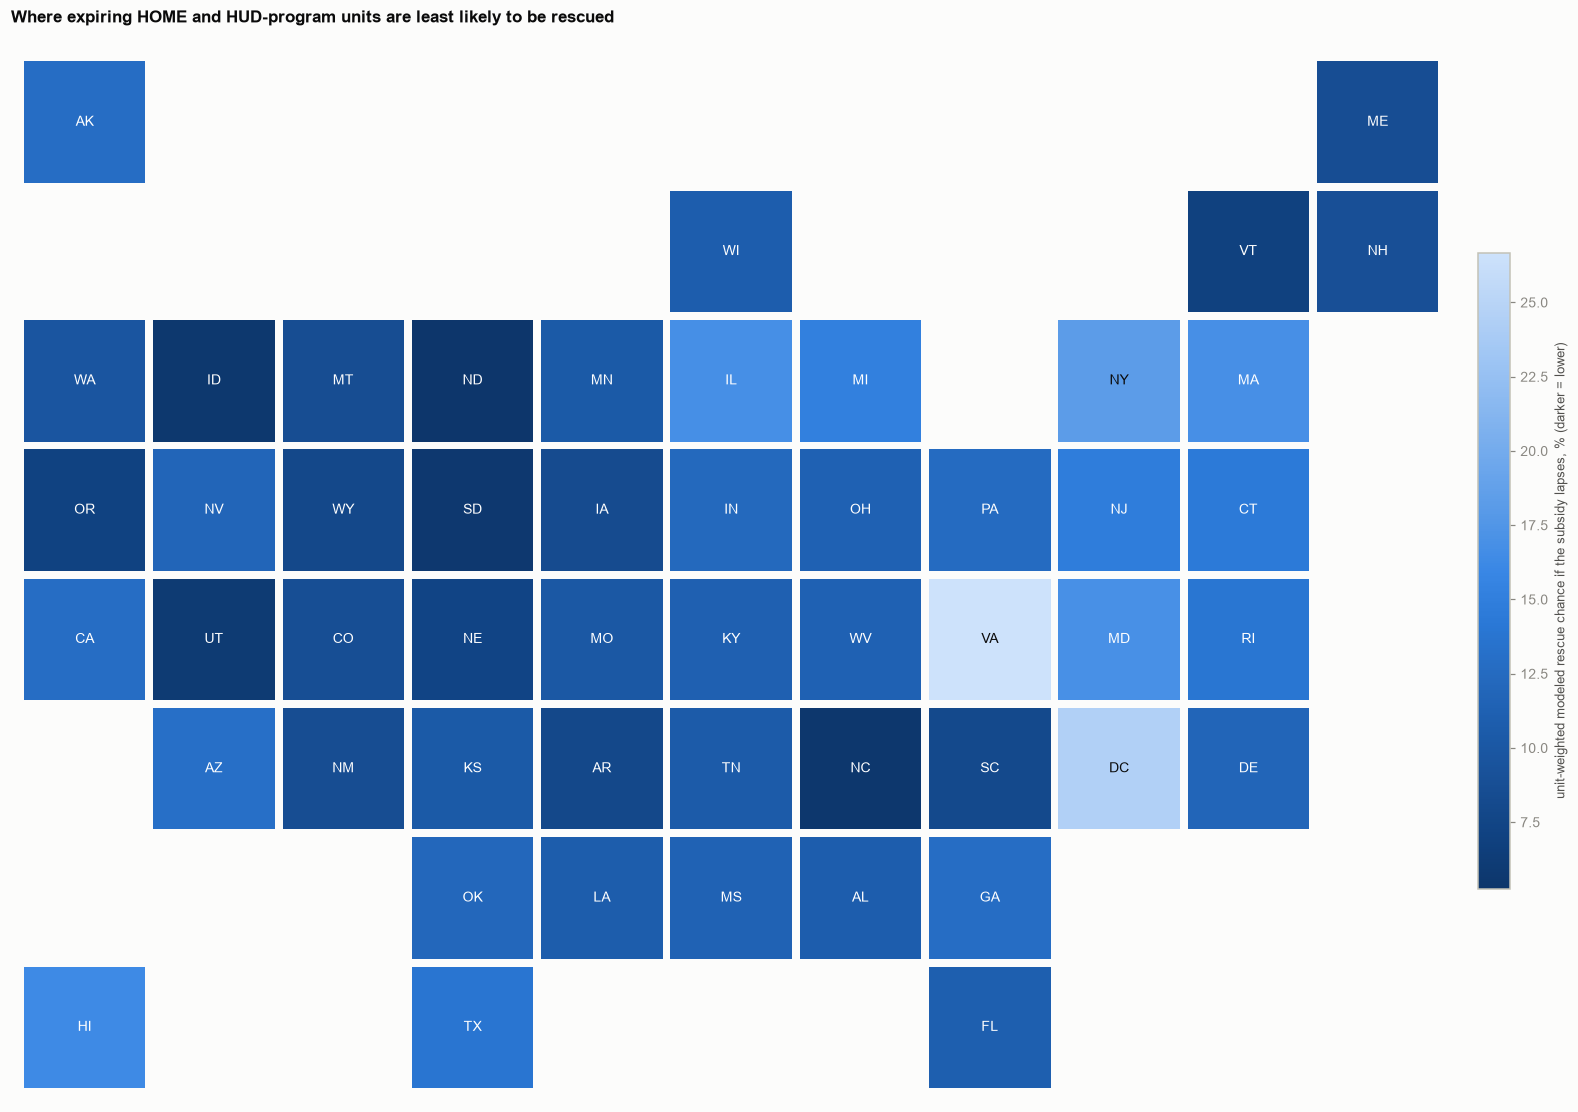

In [10]:
fig, ax = plt.subplots(figsize=(18, 10))
v = st.set_index("state").weighted_rescue_pct
m = tile_map(ax, v, cmap=SEQUENTIAL.reversed(), vmin=v.min(), vmax=v.max())
cb = fig.colorbar(m, ax=ax, shrink=0.6, pad=0.01); cb.set_label("unit-weighted modeled rescue chance if the subsidy lapses, % (darker = lower)", fontsize=8.5)
ax.set_title("Where expiring HOME and HUD-program units are least likely to be rescued", fontsize=11, loc="left")
save_figure(fig, "51_state_rescue_map", part="05_preservation")
plt.show()

## Findings

**Can it be predicted?** Yes, in one narrow sense. A logistic regression on property size alone ranks properties by their chance of being re-subsidized with an AUC of 0.82 (90 percent
interval 0.79 to 0.85) on the 2019 to 2023 events and 0.84 on the second split; average precision 0.079 against a 0.022 base rate, and the top 20 percent of properties by score contain 65 percent of those
that were rescued. Nothing beats it. Boosting reaches 0.80 (0.76 on the second split), the random forest 0.58 to 0.74, program group alone 0.58, and adding state market conditions lowers the logit from 0.83 to 0.80. The
model that works is the simple, interpretable one, which is the same lesson as the state-level work.

**What drives it: size.** Each doubling of total units multiplies the odds of rescue by 1.85 (1.66 to 2.07). For HUD-program properties the rescue rate runs from 0 percent at 1 to 10 units to 2, 5, 13, 19, and
28 percent in the next size bands up to 200 or more units; HOME-only properties follow the same slope, to 7 percent at 51 to 200 units. Once size is controlled the program group is not distinguishable (HUD odds ratio 1.64, p = 0.15).

**Rent and income conditions do not help.** The six state market variables are jointly significant in the in-sample logit (Wald chi-square 39.3, p < 0.001), but they carry no out-of-sample skill (AUC 0.51, or 0.61 on the second
split) and make the combined model worse. The rescue rate rose from 1.0 percent (2011 to 2013) to 4.2 percent (2022 to 2023), the same period that rents rose, so the in-sample link is most likely a shared time trend.
This is a result for the project's question: local market tightness does not predict whether a lapsing subsidy is rescued; property characteristics do.

**Calibration.** In the test period the highest-scored fifth is predicted at 5.1 percent and observed at 6.8 percent, but the lower fifths are under-predicted (0.7 percent predicted for 2.8 percent observed in the fourth) because the rescue rate
rose. Use the score to rank, not as a probability.

**What it says about what comes next.** 21,678 active properties have their last active subsidy ending between 2026 and 2035. The model can speak for only **41 percent of those units** (HUD-program 33 percent, HOME-only 7 percent). LIHTC (48 percent
of units) and RHS (10 percent) have almost no history in NHPD (86 and 12 events) and are not scored; the largest block of expiring affordability is therefore outside this model. Within the scored units, 30 percent sit in properties of 50 units
or fewer and 18 percent in properties with a modeled rescue chance under 5 percent. If every scored subsidy lapsed, 295,000 to 353,000 units would go unrescued; that is an **upper bound**, because the history contains only subsidies
that lapsed and many of these will be renewed first. By state the largest unrescued totals are New York (28,000 to 35,000), California (25,000 to 31,000), Pennsylvania (17,000 to 18,000), Ohio (14,000 to 17,000), and Illinois (13,000 to 16,000).
The lowest unit-weighted rescue chance is in states whose expiring stock is small properties: North Dakota (5.3 percent), North Carolina (5.5), Idaho (5.6), South Dakota (5.7), Utah (6.0), and Vermont (6.9); the highest are Virginia (26.7) and DC (24.5).

**What this implies for action (descriptive, not tested; corrected in Part 8).** Small properties are the most likely to be lost, but they hold few units: those of 25 units or fewer are 62 percent of the scored properties and 15 percent of the expected unrescued units, while properties of 51 to 200 units hold 56 percent. By units per action the efficient order is largest first (14 percent of the properties cover half the expected loss); see `notebooks/08_actions`. For LIHTC, which
holds nearly half the expiring units, the data to build such a model are not in NHPD (no record of what happened when a 30-year clock ran out), so that is the first data gap to close.

**Caveats.** A rescue is a new subsidy recorded in NHPD, so recording gaps for small properties could contribute to the size effect. HOME is 93 percent of events and its affordability periods end by design. The label is conditional on lapse. Only 58 events
are rescued in the main training period and 102 in the test, so intervals are wide. Total units come from the 2026 property file. Nothing here is causal. Tables: `outputs/tables/preservation_model_results.csv`, `preservation_state.csv`, `preservation_events.csv`.